<a href="https://colab.research.google.com/github/tsegaye12-bir/PhD-Dessertation-/blob/main/Optimized_Final_PhD_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# CELL 2: Imports & Configuration
# ============================================================
import os, json, random, time, copy, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import MultiStepLR
from torch.cuda.amp import autocast, GradScaler

import torchvision.transforms as T
from torchvision.models import resnet50, efficientnet_b4, vit_b_16

import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from scipy.stats import chi2 as chi2_dist

warnings.filterwarnings('ignore')

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
class CFG:
    # ---- Dataset root (matches your Drive structure) ----
    DATA_ROOT  = '/content/drive/MyDrive/PhD Datasets'
    LOCAL_DIR  = os.path.join(DATA_ROOT, 'Local Dataset')
    PUBLIC_DIR = os.path.join(DATA_ROOT, 'Public Dataset')
    OUTPUT_DIR = '/content/drive/MyDrive/CropXNet_Outputs'
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # ---- 12 unified classes (from paper Table 1) ----
    CLASSES = [
        'Maize_Leaf_Spot',         # 0
        'Maize_Leaf_Rust',         # 1
        'Maize_Leaf_Blight',       # 2
        'Maize_Healthy',           # 3
        'Wheat_Rust',              # 4
        'Wheat_Septoria',          # 5
        'Wheat_Healthy',           # 6
        'Coffee_Eye_Spot',         # 7
        'Coffee_Healthy',          # 8
        'Pepper_Bacterial_Spot',   # 9
        'Pepper_Leaf_Blight',      # 10 (Local-only)
        'Pepper_Healthy',          # 11
    ]
    NUM_CLASSES = 12

    # ---- Folder → unified class mapping ----
    # Structure: {crop_folder: {subfolder_name: class_index}}
    CLASS_MAPPING = {
        'Coffee Leave Disease': {
            'Brown eye spot': 7,          # Coffee_Eye_Spot
            'Healty':         8,          # Coffee_Healthy (typo in folder)
            'Healthy':        8,          # in case Public uses 'Healthy'
        },
        'Corn(maize)Leave Disease': {
            'Cercospora_leaf_spot Gray_leaf_spot': 0,   # Maize_Leaf_Spot
            'Common_rust':                          1,  # Maize_Leaf_Rust
            'Northern_Leaf_Blight':                 2,  # Maize_Leaf_Blight
            'Healthy':                              3,  # Maize_Healthy
        },
        'Pepper_bell_Leave Disease': {
            'Pepper bell_ Blight':           10,  # Pepper_Leaf_Blight
            'Pepper__bell___Blight':         10,
            'Pepper__bell___Bacterial_spot':  9,  # Pepper_Bacterial_Spot
            'Pepper__bell___healthy':        11,  # Pepper_Healthy
        },
        'wheat_leaf': {
            'Healthy':     6,     # Wheat_Healthy
            'septoria':    5,     # Wheat_Septoria
            'stripe_rust': 4,     # Wheat_Rust
        },
    }

    # ---- Image / Split ----
    IMG_SIZE = 224
    TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
    AUG_TARGET = 32000

    # ---- Training ----
    EPOCHS         = 5
    BATCH_SIZE     = 64
    ACCUM_STEPS    = 4
    LR             = 1e-4
    WEIGHT_DECAY   = 1e-4
    DROPOUT        = 0.3
    PATIENCE       = 10
    LR_DROP_EPOCHS = [30, 40]
    LR_DROP_GAMMA  = 0.1

    # ---- Architecture ----
    CNN_BACKBONE   = 'tf_efficientnetv2_s'
    VIT_EMBED_DIM  = 256
    VIT_NUM_LAYERS = 4
    VIT_NUM_HEADS  = 8
    VIT_MLP_RATIO  = 4.0
    FUSION_DIM     = 512
    MLP_HIDDEN     = 256

    # ---- Augmentation ----
    CUTMIX_PROB    = 0.3
    CUTMIX_ALPHA   = 1.0
    ERASE_PROB     = 0.2
    ROT_DEGREES    = 20
    SCALE_RANGE    = (0.8, 1.2)

    # ---- Misc ----
    DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    NUM_WORKERS = 2
    SEED        = 42

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.SEED)
print(f'Device: {CFG.DEVICE}')
print(f'Local  dir : {CFG.LOCAL_DIR}')
print(f'Public dir : {CFG.PUBLIC_DIR}')
print(f'Output dir : {CFG.OUTPUT_DIR}')

Device: cuda
Local  dir : /content/drive/MyDrive/PhD Datasets/Local Dataset
Public dir : /content/drive/MyDrive/PhD Datasets/Public Dataset
Output dir : /content/drive/MyDrive/CropXNet_Outputs


In [ ]:
# ============================================================
# CELL 3: Scan Local + Public datasets → unified DataFrame
# ============================================================
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def scan_source(base_dir, source_label):
    """Walk through crop folders, map subfolders → unified class index."""
    records = []
    if not os.path.isdir(base_dir):
        print(f'[WARN] Missing: {base_dir}')
        return pd.DataFrame(columns=['path', 'label', 'class_name', 'source', 'crop'])

    for crop_folder, submap in CFG.CLASS_MAPPING.items():
        crop_path = os.path.join(base_dir, crop_folder)
        if not os.path.isdir(crop_path):
            continue
        for sub in os.listdir(crop_path):
            sub_path = os.path.join(crop_path, sub)
            if not os.path.isdir(sub_path): continue
            if sub not in submap: continue
            label = submap[sub]
            for p in Path(sub_path).rglob('*'):
                if p.suffix.lower() in IMG_EXTS:
                    records.append({
                        'path': str(p),
                        'label': int(label),
                        'class_name': CFG.CLASSES[label],
                        'source': source_label,
                        'crop': crop_folder,
                    })
    return pd.DataFrame(records)

print('Scanning Local Dataset...')
local_df = scan_source(CFG.LOCAL_DIR, 'Local')
print(f'  Found {len(local_df)} images')

print('Scanning Public Dataset...')
public_df = scan_source(CFG.PUBLIC_DIR, 'Public')
print(f'  Found {len(public_df)} images')

df = pd.concat([local_df, public_df], ignore_index=True)

print('\n' + '=' * 60)
print(f'TOTAL IMAGES: {len(df)}')
print('=' * 60)
print(f'  Local : {len(local_df)}')
print(f'  Public: {len(public_df)}')

# ---- Distribution by class and source ----
pivot = df.pivot_table(index='class_name', columns='source',
                       values='path', aggfunc='count', fill_value=0)
pivot = pivot.reindex(CFG.CLASSES, fill_value=0)
pivot['Total'] = pivot.sum(axis=1)
print('\nClass distribution:')
print(pivot.to_string())

assert len(df) > 0, 'No images found. Check folder structure!'

Scanning Local Dataset...
  Found 11998 images
Scanning Public Dataset...
  Found 6964 images

TOTAL IMAGES: 18962
  Local : 11998
  Public: 6964

Class distribution:
source                 Local  Public  Total
class_name                                 
Maize_Leaf_Spot         1642     574   2216
Maize_Leaf_Rust         1906       0   1906
Maize_Leaf_Blight       1908    1146   3054
Maize_Healthy           1859    1162   3021
Wheat_Rust               209     208    417
Wheat_Septoria            97      97    194
Wheat_Healthy            102     102    204
Coffee_Eye_Spot         1200     600   1800
Coffee_Healthy           600     600   1200
Pepper_Bacterial_Spot    965     997   1962
Pepper_Leaf_Blight        32       0     32
Pepper_Healthy          1478    1478   2956


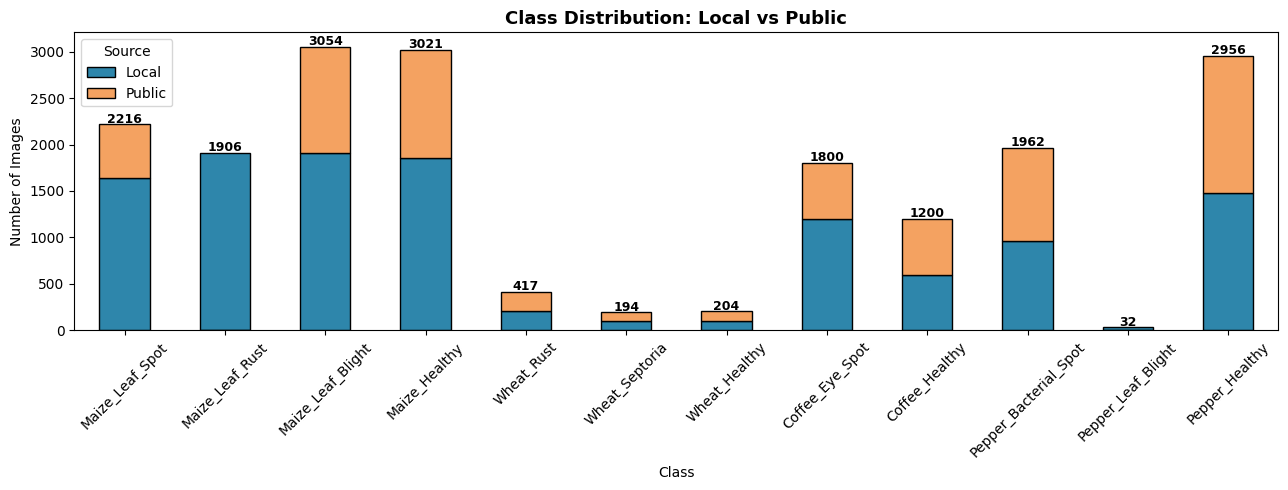

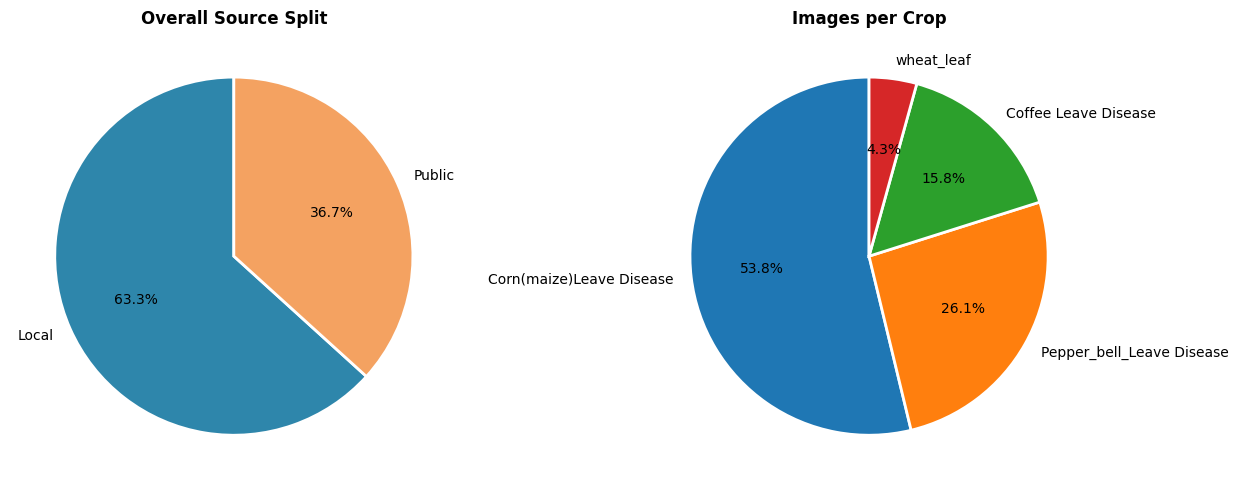

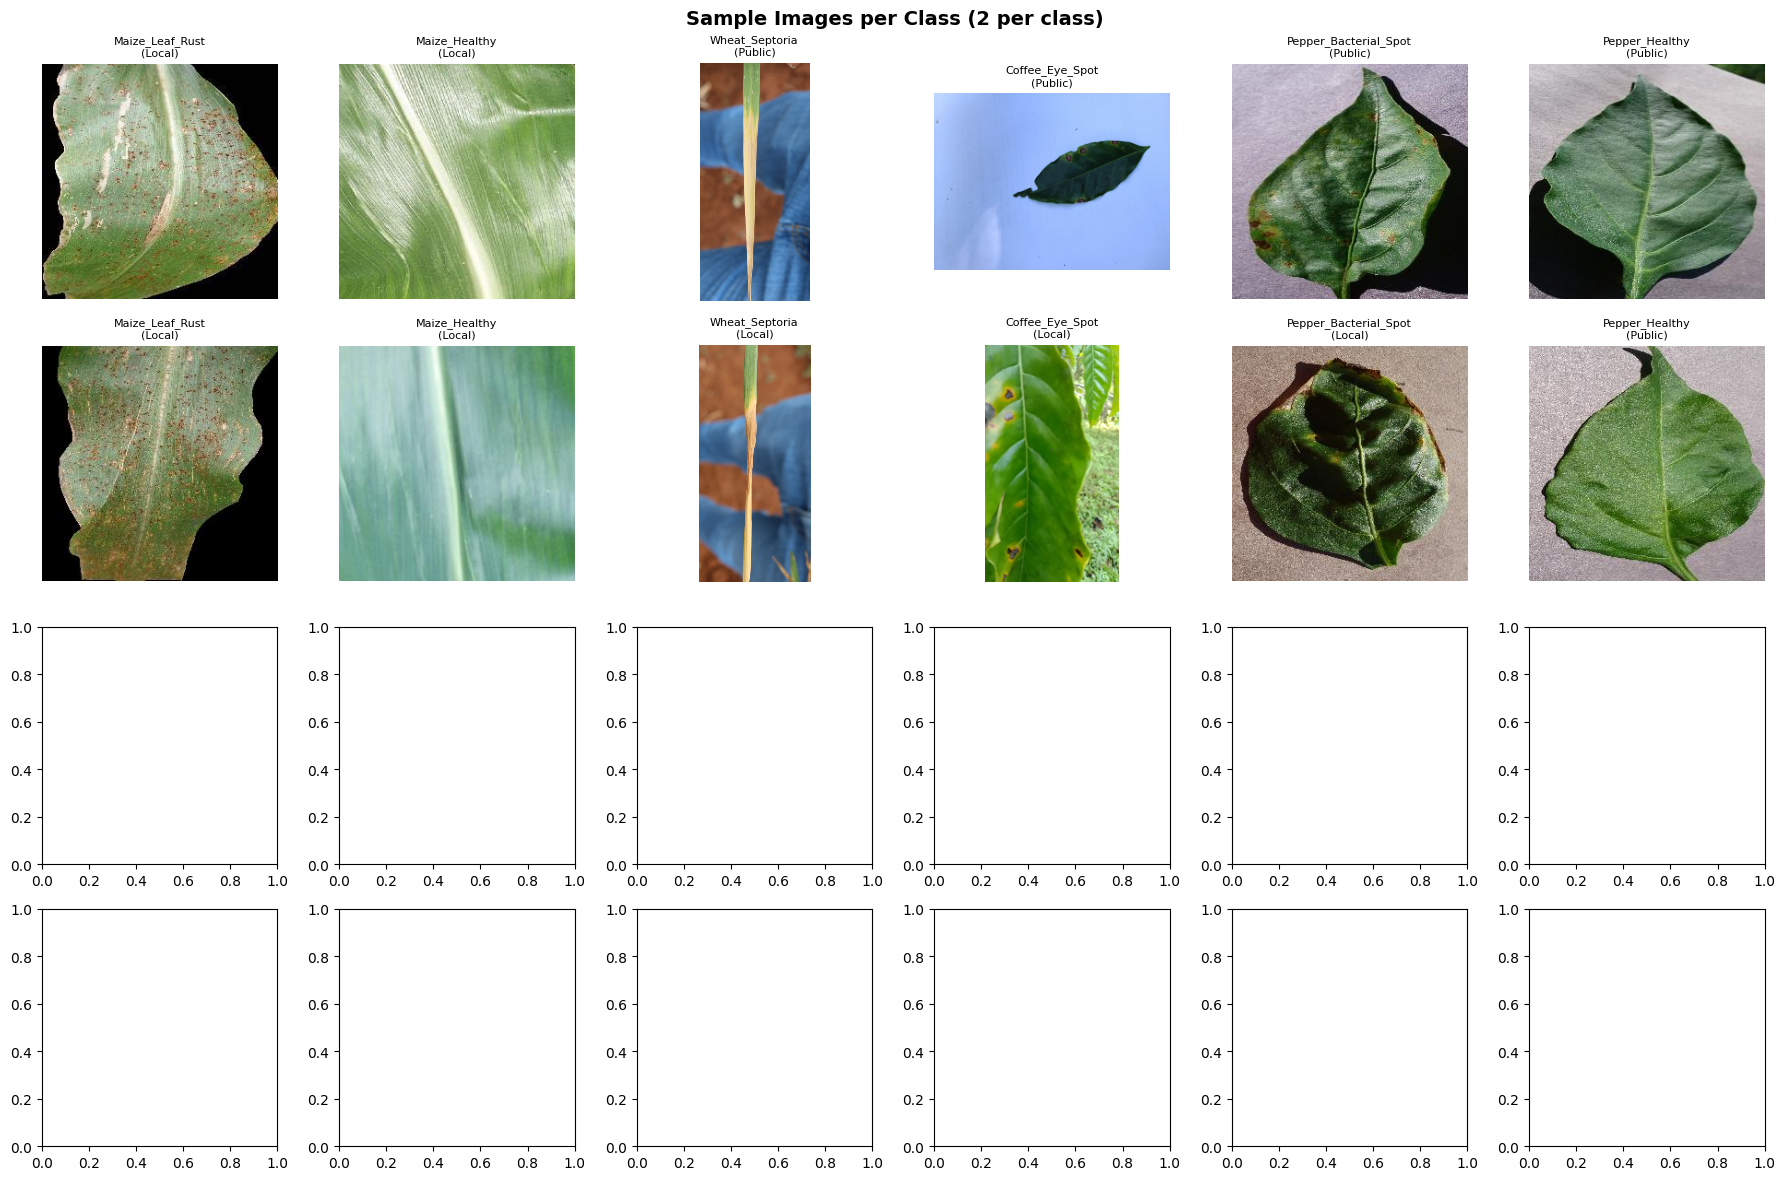

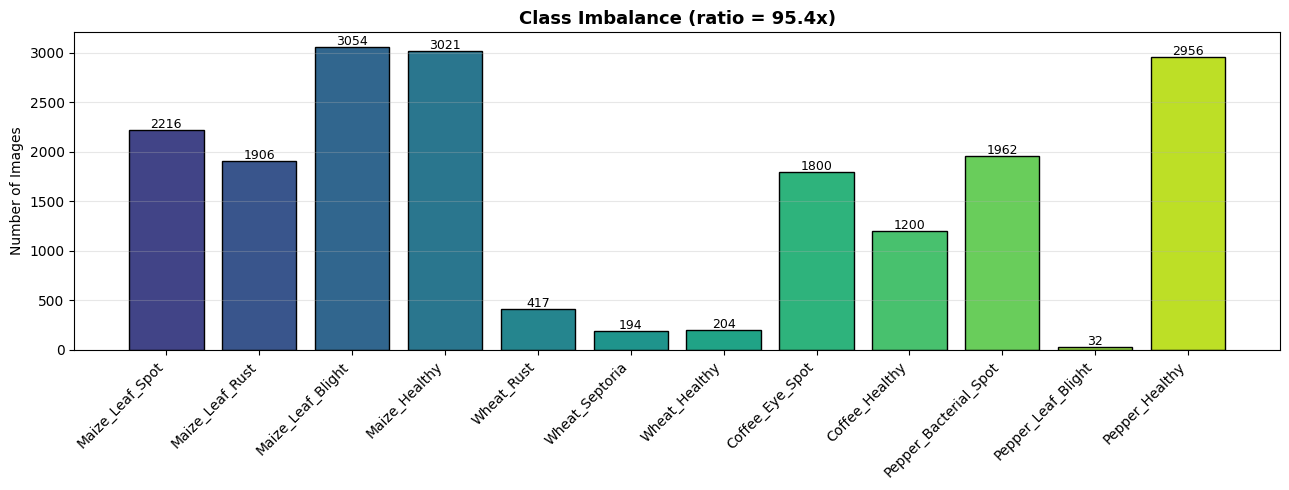

Dataset visualizations saved.


In [ ]:
# ============================================================
# CELL 4: Dataset Visualizations
# ============================================================

# ---- 4.1 Class distribution (stacked bar: Local + Public) ----
fig, ax = plt.subplots(figsize=(13, 5))
pivot[['Local', 'Public']].plot(kind='bar', stacked=True, ax=ax,
                                color=['#2E86AB', '#F4A261'], edgecolor='black')
ax.set_title('Class Distribution: Local vs Public', fontsize=13, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('Number of Images')
ax.tick_params(axis='x', rotation=45)
for i, (loc, pub) in enumerate(zip(pivot['Local'], pivot['Public'])):
    ax.text(i, loc + pub + 20, f'{int(loc+pub)}', ha='center', fontsize=9, fontweight='bold')
ax.legend(title='Source'); plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/dataset_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- 4.2 Source pie chart ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie([len(local_df), len(public_df)],
            labels=['Local', 'Public'], autopct='%1.1f%%',
            colors=['#2E86AB', '#F4A261'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Overall Source Split', fontweight='bold')

crop_counts = df['crop'].value_counts()
axes[1].pie(crop_counts.values, labels=crop_counts.index,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Images per Crop', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/dataset_source_pie.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- 4.3 Sample images grid (2 per class) ----
n_cols, n_rows = 6, 4   # 12 classes × 2 = 24 images
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))
for ci, cname in enumerate(CFG.CLASSES):
    subset = df[df['class_name'] == cname]
    if len(subset) == 0:
        continue
    samples = subset.sample(min(2, len(subset)), random_state=42)
    for j, (_, row) in enumerate(samples.iterrows()):
        ax = axes[j, ci // 2] if n_rows == 4 else axes.flat[ci * 2 + j]
        try:
            ax.imshow(Image.open(row['path']).convert('RGB'))
            ax.set_title(f"{cname}\n({row['source']})", fontsize=8)
        except Exception:
            ax.text(0.5, 0.5, 'ERR', ha='center')
        ax.axis('off')
plt.suptitle('Sample Images per Class (2 per class)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/dataset_samples.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- 4.4 Class imbalance ratio ----
counts = df['class_name'].value_counts().reindex(CFG.CLASSES)
fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(counts)), counts.values,
              color=plt.cm.viridis(np.linspace(0.2, 0.9, len(counts))),
              edgecolor='black')
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=45, ha='right')
ax.set_ylabel('Number of Images')
ax.set_title(f'Class Imbalance (ratio = {counts.max()/max(counts.min(),1):.1f}x)',
             fontsize=13, fontweight='bold')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 20, str(int(v)),
            ha='center', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/dataset_imbalance.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

print('Dataset visualizations saved.')

In [ ]:
# ============================================================
# CELL 5: DataLoaders & Augmentation
# ============================================================
def stratified_split(df):
    """70/15/15 stratified split."""
    train_df, temp_df = train_test_split(
        df, test_size=(CFG.VAL_RATIO + CFG.TEST_RATIO),
        stratify=df['label'], random_state=CFG.SEED)
    val_df, test_df = train_test_split(
        temp_df, test_size=CFG.TEST_RATIO / (CFG.VAL_RATIO + CFG.TEST_RATIO),
        stratify=temp_df['label'], random_state=CFG.SEED)
    return (train_df.reset_index(drop=True),
            val_df.reset_index(drop=True),
            test_df.reset_index(drop=True))

train_df, val_df, test_df = stratified_split(df)
print(f'Train: {len(train_df)}   Val: {len(val_df)}   Test: {len(test_df)}')

# ---- Transforms ----
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfms = T.Compose([
    T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomApply([T.RandomRotation(degrees=CFG.ROT_DEGREES)], p=0.5),
    T.RandomApply([T.RandomAffine(degrees=0, scale=CFG.SCALE_RANGE)], p=0.5),
    T.ColorJitter(brightness=0.3, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    T.RandomErasing(p=CFG.ERASE_PROB, scale=(0.02, 0.2)),
])

eval_tfms = T.Compose([
    T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class LeafDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row['path']).convert('RGB')
        return self.transform(img), int(row['label'])

def make_loaders(train_df, val_df, test_df):
    train_ds = LeafDataset(train_df, train_tfms)
    val_ds   = LeafDataset(val_df,   eval_tfms)
    test_ds  = LeafDataset(test_df,  eval_tfms)

    n_per_epoch = min(CFG.AUG_TARGET, len(train_ds) * 3)
    sampler = WeightedRandomSampler(
        weights=torch.ones(len(train_ds)),
        num_samples=n_per_epoch, replacement=True)

    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE,
                              sampler=sampler, num_workers=CFG.NUM_WORKERS,
                              pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE,
                              shuffle=False, num_workers=CFG.NUM_WORKERS,
                              pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=CFG.BATCH_SIZE,
                              shuffle=False, num_workers=CFG.NUM_WORKERS,
                              pin_memory=True)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df)
print(f'Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

# ---- Class weights (Eq. 3) ----
def compute_class_weights(labels, num_classes):
    counts = np.bincount(labels, minlength=num_classes).astype(np.float64)
    counts[counts == 0] = 1.0
    return torch.FloatTensor(len(labels) / (num_classes * counts))

class_weights = compute_class_weights(train_df['label'].values, CFG.NUM_CLASSES)
print('Class weights:', class_weights.numpy().round(3))

# ---- CutMix ----
def cutmix_batch(x, y, alpha=CFG.CUTMIX_ALPHA, prob=CFG.CUTMIX_PROB):
    if random.random() > prob:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    B, C, H, W = x.shape
    idx = torch.randperm(B, device=x.device)
    cut_rat = math.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_rat), int(H * cut_rat)
    cx, cy = np.random.randint(W), np.random.randint(H)
    x1, y1 = np.clip(cx - cut_w // 2, 0, W), np.clip(cy - cut_h // 2, 0, H)
    x2, y2 = np.clip(cx + cut_w // 2, 0, W), np.clip(cy + cut_h // 2, 0, H)
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1.0 - ((x2 - x1) * (y2 - y1) / (W * H))
    return x, y, y[idx], lam

criterion_eval = nn.CrossEntropyLoss()
all_overall, all_reports, all_preds, all_models = {}, {}, {}, {}

Train: 13273   Val: 2844   Test: 2845
Train batches: 500 | Val: 45 | Test: 45
Class weights: [ 0.713  0.829  0.517  0.523  3.788  8.133  7.735  0.878  1.317  0.806
 50.277  0.535]


In [ ]:
# ============================================================
# CELL 6: Model Architectures
# ============================================================

# ---- Compact ViT ----
class CompactViT(nn.Module):
    def __init__(self, in_ch=1280, embed_dim=256, num_layers=4,
                 num_heads=8, mlp_ratio=4.0, dropout=0.3,
                 num_patches=49, out_dim=512):
        super().__init__()
        self.patch_embed = nn.Linear(in_ch, embed_dim)
        self.pos_embed   = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation='gelu',
            batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(embed_dim)
        self.proj = nn.Linear(embed_dim, out_dim)

    def forward(self, feat_map):
        x = feat_map.flatten(2).transpose(1, 2)
        x = self.patch_embed(x) + self.pos_embed
        x = self.encoder(x)
        return self.proj(self.norm(x).mean(dim=1))

# ---- Gated Fusion ----
class GatedFusion(nn.Module):
    def __init__(self, dim=512):
        super().__init__()
        self.W_g = nn.Linear(2 * dim, dim)
        self.b_g = nn.Parameter(torch.zeros(dim))
    def forward(self, f_cnn, f_vit):
        g = torch.sigmoid(self.W_g(torch.cat([f_cnn, f_vit], -1)) + self.b_g)
        return g * f_cnn + (1.0 - g) * f_vit, g

# ---- CropXNet-Hybrid ----
class CropXNetHybrid(nn.Module):
    def __init__(self, num_classes=12, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model(CFG.CNN_BACKBONE, pretrained=True,
                                     features_only=True, out_indices=[-1])
        cnn_ch = self.cnn.feature_info.channels()[-1]
        self.cnn_pool = nn.AdaptiveAvgPool2d(1)
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_ch, CFG.FUSION_DIM), nn.BatchNorm1d(CFG.FUSION_DIM),
            nn.GELU(), nn.Dropout(dropout))
        self.vit = CompactViT(in_ch=cnn_ch, embed_dim=CFG.VIT_EMBED_DIM,
                              num_layers=CFG.VIT_NUM_LAYERS,
                              num_heads=CFG.VIT_NUM_HEADS,
                              mlp_ratio=CFG.VIT_MLP_RATIO,
                              dropout=dropout, out_dim=CFG.FUSION_DIM)
        self.fusion = GatedFusion(dim=CFG.FUSION_DIM)
        self.classifier = nn.Sequential(
            nn.Linear(CFG.FUSION_DIM, CFG.MLP_HIDDEN), nn.BatchNorm1d(CFG.MLP_HIDDEN),
            nn.GELU(), nn.Dropout(dropout),
            nn.Linear(CFG.MLP_HIDDEN, num_classes))

    def forward(self, x):
        fm = self.cnn(x)[0]
        f_cnn = self.cnn_proj(self.cnn_pool(fm).flatten(1))
        f_vit = self.vit(fm)
        f_fused, _ = self.fusion(f_cnn, f_vit)
        return self.classifier(f_fused)

# ---- Variant A: CNN-Only ----
class CNNOnly(nn.Module):
    def __init__(self, num_classes=12, dropout=0.3):
        super().__init__()
        self.backbone = timm.create_model(CFG.CNN_BACKBONE, pretrained=True,
                                          num_classes=0)
        self.classifier = nn.Sequential(
            nn.Linear(self.backbone.num_features, CFG.FUSION_DIM),
            nn.BatchNorm1d(CFG.FUSION_DIM), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(CFG.FUSION_DIM, CFG.MLP_HIDDEN),
            nn.BatchNorm1d(CFG.MLP_HIDDEN), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(CFG.MLP_HIDDEN, num_classes))
    def forward(self, x): return self.classifier(self.backbone(x))

# ---- Variant B: ViT-Only ----
class ViTOnly(nn.Module):
    def __init__(self, num_classes=12, dropout=0.3):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, CFG.VIT_EMBED_DIM, kernel_size=16, stride=16)
        self.pos_embed = nn.Parameter(torch.zeros(1, 196, CFG.VIT_EMBED_DIM))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=CFG.VIT_EMBED_DIM, nhead=CFG.VIT_NUM_HEADS,
            dim_feedforward=int(CFG.VIT_EMBED_DIM * CFG.VIT_MLP_RATIO),
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=CFG.VIT_NUM_LAYERS)
        self.norm = nn.LayerNorm(CFG.VIT_EMBED_DIM)
        self.classifier = nn.Sequential(
            nn.Linear(CFG.VIT_EMBED_DIM, CFG.MLP_HIDDEN), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(CFG.MLP_HIDDEN, num_classes))
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2) + self.pos_embed
        return self.classifier(self.norm(self.encoder(x)).mean(1))

# ---- Variant C: Simple Fusion ----
class SimpleFusion(nn.Module):
    def __init__(self, num_classes=12, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model(CFG.CNN_BACKBONE, pretrained=True,
                                     features_only=True, out_indices=[-1])
        cnn_ch = self.cnn.feature_info.channels()[-1]
        self.cnn_pool = nn.AdaptiveAvgPool2d(1)
        self.cnn_proj = nn.Linear(cnn_ch, CFG.FUSION_DIM)
        self.vit = CompactViT(in_ch=cnn_ch, embed_dim=CFG.VIT_EMBED_DIM,
                              num_layers=CFG.VIT_NUM_LAYERS,
                              num_heads=CFG.VIT_NUM_HEADS,
                              mlp_ratio=CFG.VIT_MLP_RATIO,
                              dropout=dropout, out_dim=CFG.FUSION_DIM)
        self.classifier = nn.Sequential(
            nn.Linear(2 * CFG.FUSION_DIM, CFG.MLP_HIDDEN),
            nn.BatchNorm1d(CFG.MLP_HIDDEN), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(CFG.MLP_HIDDEN, num_classes))
    def forward(self, x):
        fm = self.cnn(x)[0]
        f_cnn = self.cnn_proj(self.cnn_pool(fm).flatten(1))
        f_vit = self.vit(fm)
        return self.classifier(torch.cat([f_cnn, f_vit], -1))

# ---- Baselines ----
def build_resnet50(nc=12):
    m = resnet50(weights='IMAGENET1K_V2'); m.fc = nn.Linear(m.fc.in_features, nc); return m
def build_effnetb4(nc=12):
    m = efficientnet_b4(weights='IMAGENET1K_V1')
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, nc); return m
def build_vitbase(nc=12):
    m = vit_b_16(weights='IMAGENET1K_V1')
    m.heads.head = nn.Linear(m.heads.head.in_features, nc); return m

def build_model(name, num_classes=12):
    name = name.lower()
    return {
        'cropxnet':      lambda: CropXNetHybrid(num_classes),
        'cnn_only':      lambda: CNNOnly(num_classes),
        'vit_only':      lambda: ViTOnly(num_classes),
        'simple_fusion': lambda: SimpleFusion(num_classes),
        'resnet50':      lambda: build_resnet50(num_classes),
        'effnetb4':      lambda: build_effnetb4(num_classes),
        'vitbase':       lambda: build_vitbase(num_classes),
    }[name]()

In [ ]:
# ============================================================
# CELL 7: Training / Evaluation Utilities
# ============================================================

def train_one_epoch(model, loader, optimizer, scaler, criterion, device, accum=4):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(loader, desc='train', leave=False)
    for step, (x, y) in enumerate(pbar):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        x, y_a, y_b, lam = cutmix_batch(x, y)
        with autocast():
            out = model(x)
            loss = (lam * criterion(out, y_a) + (1 - lam) * criterion(out, y_b)) / accum
        scaler.scale(loss).backward()
        if (step + 1) % accum == 0 or (step + 1) == len(loader):
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
        total_loss += loss.item() * accum * x.size(0)
        preds = out.argmax(1)
        correct += (lam * (preds == y_a).sum().item()
                    + (1 - lam) * (preds == y_b).sum().item())
        total += x.size(0)
        pbar.set_postfix(loss=f'{total_loss/total:.4f}', acc=f'{correct/total:.3f}')
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast():
            out = model(x); loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        preds = out.argmax(1)
        correct += (preds == y).sum().item(); total += x.size(0)
        all_preds.extend(preds.cpu().numpy()); all_labels.extend(y.cpu().numpy())
    return total_loss/total, correct/total, np.array(all_preds), np.array(all_labels)

def train_model(model_name, train_loader, val_loader,
                class_weights, device, epochs=CFG.EPOCHS, tag=''):
    model = build_model(model_name).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY,
                      betas=(0.9, 0.999), eps=1e-8)
    scheduler = MultiStepLR(optimizer, milestones=CFG.LR_DROP_EPOCHS, gamma=CFG.LR_DROP_GAMMA)
    scaler = GradScaler()
    best_val_loss, best_state, patience_cnt = float('inf'), None, 0
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler,
                                          criterion, device, accum=CFG.ACCUM_STEPS)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()
        hist['train_loss'].append(tr_loss); hist['train_acc'].append(tr_acc)
        hist['val_loss'].append(va_loss);   hist['val_acc'].append(va_acc)
        print(f'[{tag}][{model_name}] Ep {ep:02d}/{epochs} '
              f'| trL {tr_loss:.4f} trA {tr_acc:.4f} | vaL {va_loss:.4f} vaA {va_acc:.4f}')
        if va_loss < best_val_loss:
            best_val_loss, best_state, patience_cnt = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            patience_cnt += 1
            if patience_cnt >= CFG.PATIENCE:
                print(f'  Early stopping at epoch {ep}.'); break
    model.load_state_dict(best_state)
    return model, hist

def mcnemar_test(y_true, pred_a, pred_b):
    a_ok = (pred_a == y_true); b_ok = (pred_b == y_true)
    n01 = int(np.sum(~a_ok & b_ok)); n10 = int(np.sum(a_ok & ~b_ok))
    if n01 + n10 == 0: return 0.0, 1.0
    chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    return chi2, 1.0 - chi2_dist.cdf(chi2, df=1)

def evaluate_and_report(model, test_loader, hist, model_name,
                        class_names, out_dir, device):
    """Curves + Confusion Matrix + Classification Report for one model."""
    os.makedirs(out_dir, exist_ok=True)

    # ---- 1) Curves ----
    if hist is not None:
        epochs = range(1, len(hist['train_acc']) + 1)
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
        ax[0].plot(epochs, hist['train_acc'], 'o-', label='Train Acc', color='tab:blue')
        ax[0].plot(epochs, hist['val_acc'],   's-', label='Val Acc',   color='tab:orange')
        ax[0].set_title(f'{model_name} — Accuracy', fontweight='bold')
        ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
        ax[0].grid(alpha=0.3); ax[0].legend()
        ax[1].plot(epochs, hist['train_loss'], 'o-', label='Train Loss', color='tab:red')
        ax[1].plot(epochs, hist['val_loss'],   's-', label='Val Loss',   color='tab:green')
        ax[1].set_title(f'{model_name} — Loss', fontweight='bold')
        ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
        ax[1].grid(alpha=0.3); ax[1].legend()
        plt.suptitle(f'{model_name}: Training Dynamics', fontweight='bold')
        plt.tight_layout()
        p = f'{out_dir}/{model_name}_curves.png'
        plt.savefig(p, dpi=150, bbox_inches='tight')
        plt.show(); plt.close()
        print(f'  [saved] Curves          -> {p}')

    # ---- 2) Predictions ----
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            with autocast(): out = model(x)
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(y.numpy())
    y_true, y_pred = np.array(all_labels), np.array(all_preds)

    # ---- 3) Confusion Matrix (raw + normalized) ----
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar=True, ax=axes[0], annot_kws={'size': 8})
    axes[0].set_title(f'{model_name} — Confusion Matrix (counts)', fontweight='bold')
    axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')
    axes[0].tick_params(axis='x', rotation=45, labelsize=8)
    axes[0].tick_params(axis='y', rotation=0,  labelsize=8)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names,
                cbar=True, ax=axes[1], annot_kws={'size': 8}, vmin=0, vmax=1)
    axes[1].set_title(f'{model_name} — Confusion Matrix (normalized)', fontweight='bold')
    axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')
    axes[1].tick_params(axis='x', rotation=45, labelsize=8)
    axes[1].tick_params(axis='y', rotation=0,  labelsize=8)
    plt.tight_layout()
    p = f'{out_dir}/{model_name}_confusion_matrix.png'
    plt.savefig(p, dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print(f'  [saved] Confusion matrix -> {p}')

    # ---- 4) Classification Report ----
    report_dict = classification_report(y_true, y_pred, target_names=class_names,
                                        digits=4, zero_division=0, output_dict=True)
    report_df = pd.DataFrame(report_dict).transpose()
    print(f'\n===== Classification Report — {model_name} =====')
    print(classification_report(y_true, y_pred, target_names=class_names,
                                digits=4, zero_division=0))
    p = f'{out_dir}/{model_name}_classification_report.csv'
    report_df.to_csv(p)
    print(f'  [saved] Classification report -> {p}')

    overall = {
        'Model':     model_name,
        'Accuracy':  accuracy_score(y_true, y_pred) * 100,
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'Recall':    recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'F1':        f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }
    return overall, y_true, y_pred, cm, cm_norm, report_df


######################################################################
#  MODEL 1/7 : CropXNet-Hybrid (Proposed)
######################################################################


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

train:   0%|          | 0/500 [00:00<?, ?it/s]

[CropXNet][cropxnet] Ep 01/5 | trL 0.8148 trA 0.7948 | vaL 0.1210 vaA 0.9761


...

train:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[CropXNet][cropxnet] Ep 04/5 | trL 0.2601 trA 0.9078 | vaL 0.1111 vaA 0.9863


train:   0%|          | 0/500 [00:00<?, ?it/s]

[CropXNet][cropxnet] Ep 05/5 | trL 0.2297 trA 0.9111 | vaL 0.1710 vaA 0.9877


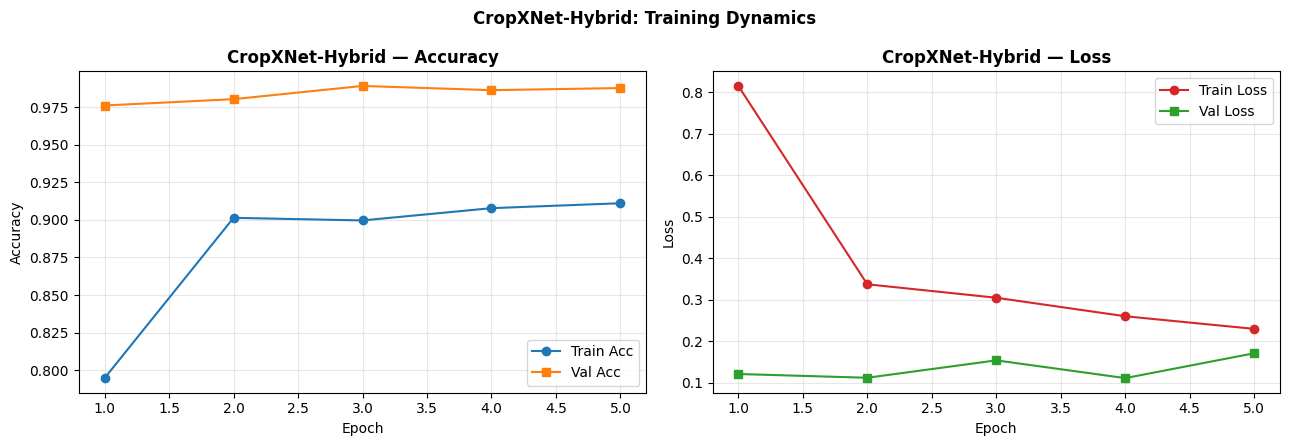

  [saved] Curves          -> /content/drive/MyDrive/CropXNet_Outputs/CropXNet-Hybrid_curves.png


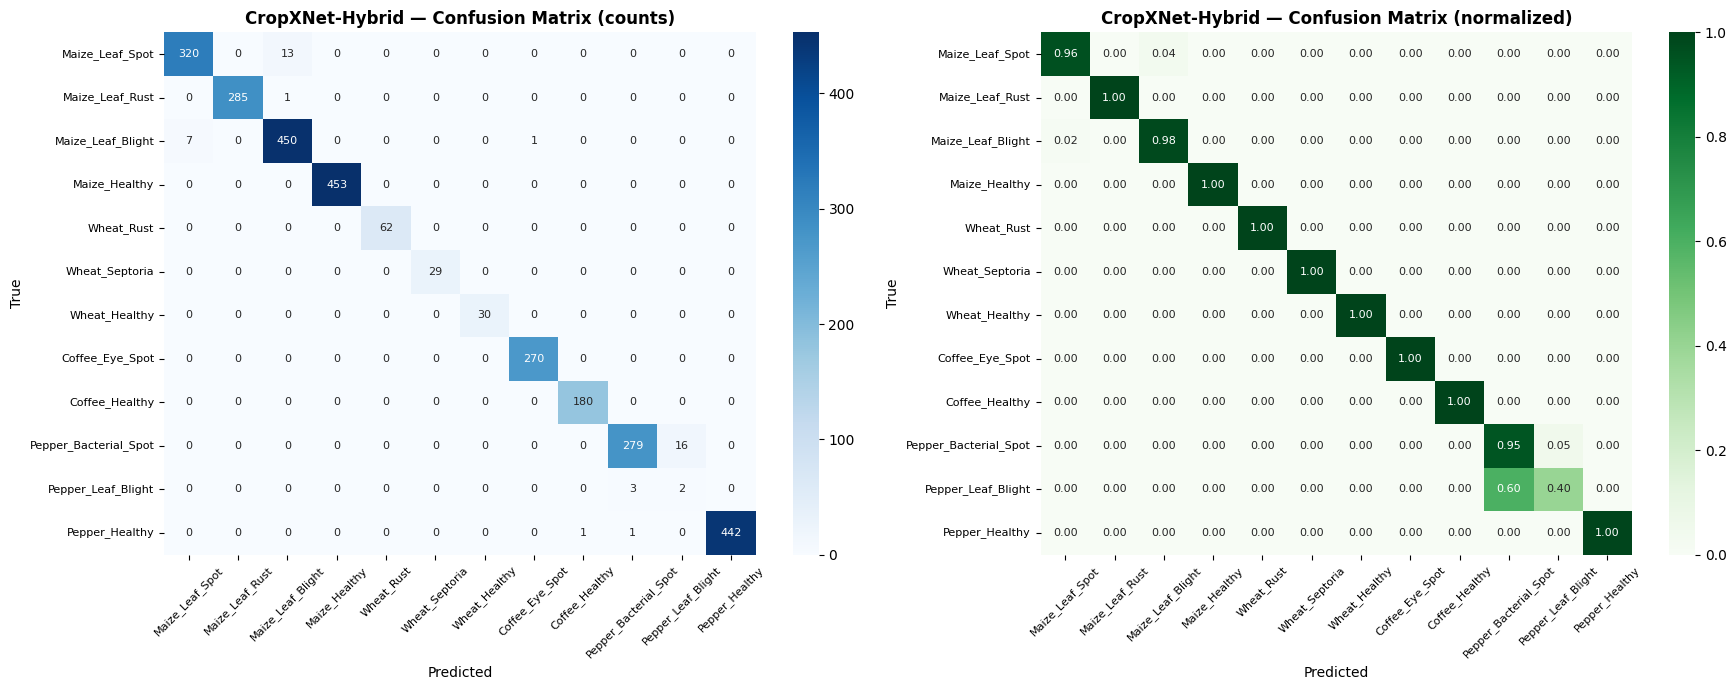

  [saved] Confusion matrix -> /content/drive/MyDrive/CropXNet_Outputs/CropXNet-Hybrid_confusion_matrix.png

===== Classification Report — CropXNet-Hybrid =====
                       precision    recall  f1-score   support

      Maize_Leaf_Spot     0.9786    0.9610    0.9697       333
      Maize_Leaf_Rust     1.0000    0.9965    0.9982       286
    Maize_Leaf_Blight     0.9698    0.9825    0.9761       458
        Maize_Healthy     1.0000    1.0000    1.0000       453
           Wheat_Rust     1.0000    1.0000    1.0000        62
       Wheat_Septoria     1.0000    1.0000    1.0000        29
        Wheat_Healthy     1.0000    1.0000    1.0000        30
      Coffee_Eye_Spot     0.9963    1.0000    0.9982       270
       Coffee_Healthy     0.9945    1.0000    0.9972       180
Pepper_Bacterial_Spot     0.9859    0.9458    0.9654       295
   Pepper_Leaf_Blight     0.1111    0.4000    0.1739         5
       Pepper_Healthy     1.0000    0.9955    0.9977       444

             accura

In [ ]:
# ============================================================
# CELL 8: MODEL 1/7 — CropXNet-Hybrid (Proposed)
# ============================================================
print('\n' + '#' * 70)
print('#  MODEL 1/7 : CropXNet-Hybrid (Proposed)')
print('#' * 70)

m, h = train_model('cropxnet', train_loader, val_loader,
                   class_weights, CFG.DEVICE, epochs=CFG.EPOCHS, tag='CropXNet')

overall, yt, yp, cm, cmn, rpt = evaluate_and_report(
    m, test_loader, h, model_name='CropXNet-Hybrid',
    class_names=CFG.CLASSES, out_dir=CFG.OUTPUT_DIR, device=CFG.DEVICE)

overall['Params (M)'] = sum(p.numel() for p in m.parameters()) / 1e6
all_overall['CropXNet-Hybrid'] = overall
all_reports['CropXNet-Hybrid'] = rpt
all_preds['CropXNet-Hybrid']   = (yt, yp)
all_models['CropXNet-Hybrid']  = m
torch.save(m.state_dict(), f'{CFG.OUTPUT_DIR}/CropXNet-Hybrid_best.pth')


######################################################################
#  ABLATION : CNN-Only
######################################################################


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][cnn_only] Ep 01/5 | trL 0.9932 trA 0.7680 | vaL 0.1805 vaA 0.9694


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][cnn_only] Ep 02/5 | trL 0.4249 trA 0.8833 | vaL 0.1393 vaA 0.9800


...

train:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Abl][cnn_only] Ep 04/5 | trL 0.3208 trA 0.8913 | vaL 0.0937 vaA 0.9887


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][cnn_only] Ep 05/5 | trL 0.2702 trA 0.9059 | vaL 0.1189 vaA 0.9891


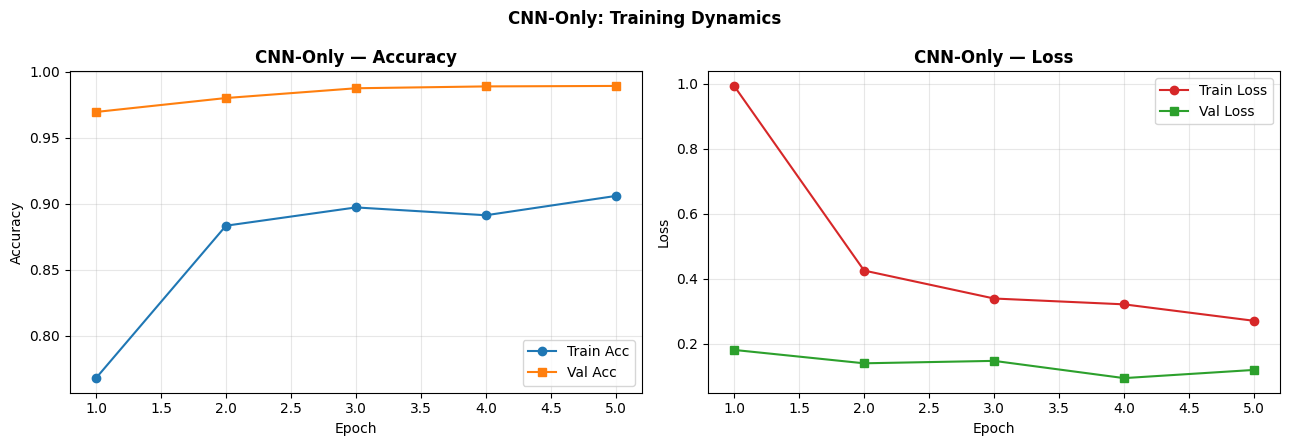

  [saved] Curves          -> /content/drive/MyDrive/CropXNet_Outputs/CNN-Only_curves.png


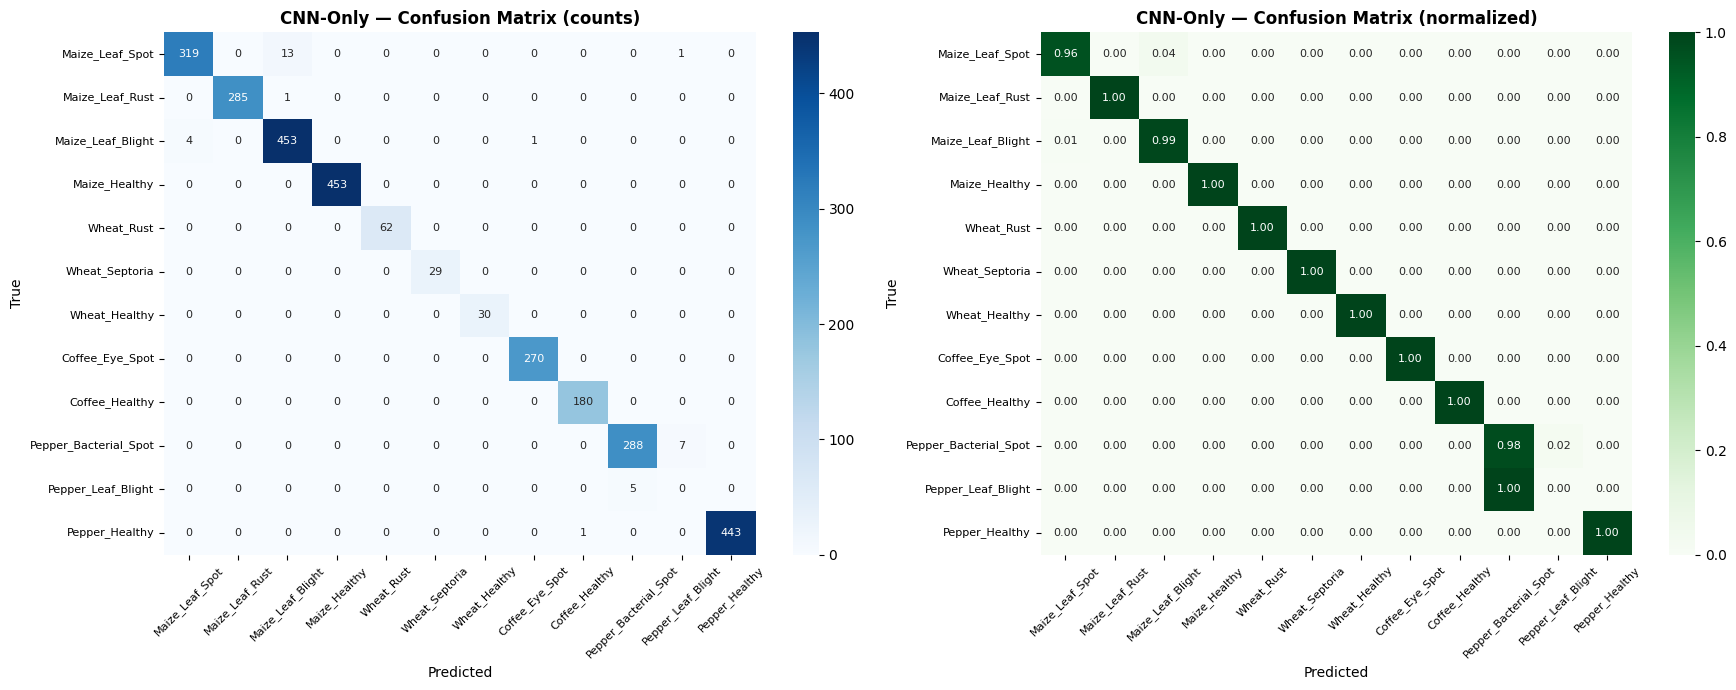

  [saved] Confusion matrix -> /content/drive/MyDrive/CropXNet_Outputs/CNN-Only_confusion_matrix.png

===== Classification Report — CNN-Only =====
                       precision    recall  f1-score   support

      Maize_Leaf_Spot     0.9876    0.9580    0.9726       333
      Maize_Leaf_Rust     1.0000    0.9965    0.9982       286
    Maize_Leaf_Blight     0.9700    0.9891    0.9795       458
        Maize_Healthy     1.0000    1.0000    1.0000       453
           Wheat_Rust     1.0000    1.0000    1.0000        62
       Wheat_Septoria     1.0000    1.0000    1.0000        29
        Wheat_Healthy     1.0000    1.0000    1.0000        30
      Coffee_Eye_Spot     0.9963    1.0000    0.9982       270
       Coffee_Healthy     0.9945    1.0000    0.9972       180
Pepper_Bacterial_Spot     0.9829    0.9763    0.9796       295
   Pepper_Leaf_Blight     0.0000    0.0000    0.0000         5
       Pepper_Healthy     1.0000    0.9977    0.9989       444

             accuracy            

train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][vit_only] Ep 01/5 | trL 1.6815 trA 0.4978 | vaL 0.8027 vaA 0.7982


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][vit_only] Ep 02/5 | trL 1.0729 trA 0.6890 | vaL 0.5941 vaA 0.8298


...

train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][vit_only] Ep 04/5 | trL 0.7975 trA 0.7644 | vaL 0.3368 vaA 0.8924


train:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Abl][vit_only] Ep 05/5 | trL 0.7436 trA 0.7770 | vaL 0.3608 vaA 0.9033


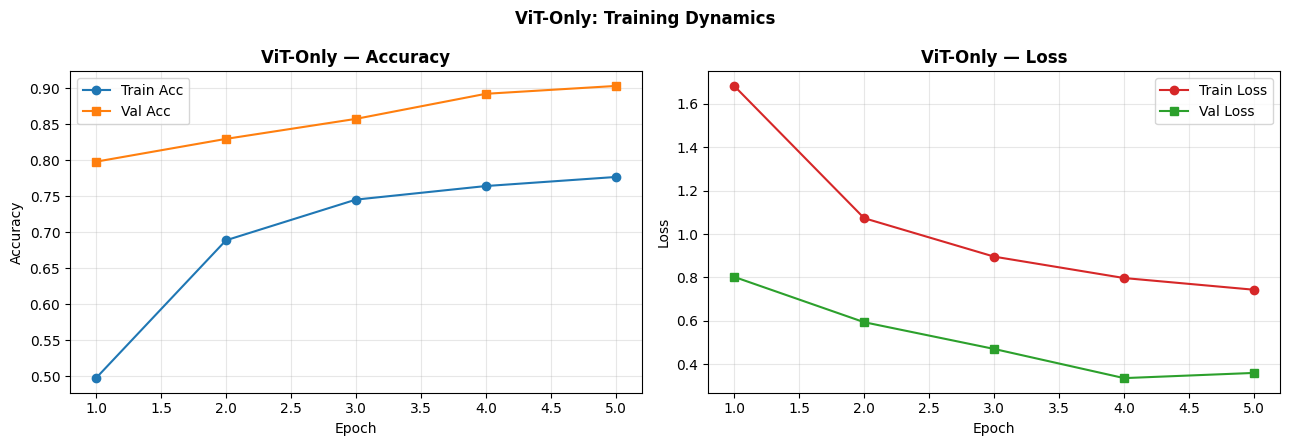

  [saved] Curves          -> /content/drive/MyDrive/CropXNet_Outputs/ViT-Only_curves.png


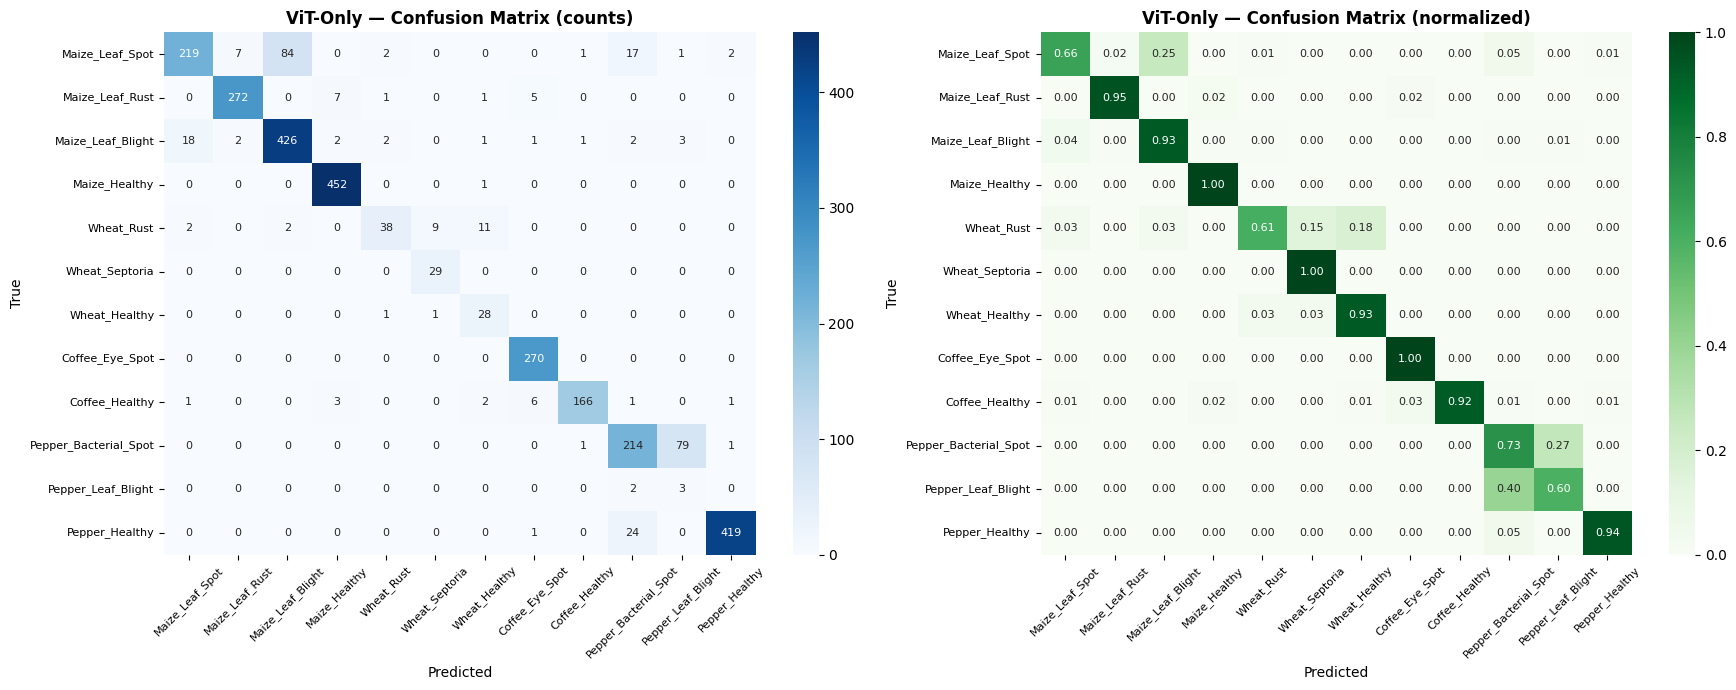

  [saved] Confusion matrix -> /content/drive/MyDrive/CropXNet_Outputs/ViT-Only_confusion_matrix.png

===== Classification Report — ViT-Only =====
                       precision    recall  f1-score   support

      Maize_Leaf_Spot     0.9125    0.6577    0.7644       333
      Maize_Leaf_Rust     0.9680    0.9510    0.9594       286
    Maize_Leaf_Blight     0.8320    0.9301    0.8784       458
        Maize_Healthy     0.9741    0.9978    0.9858       453
           Wheat_Rust     0.8636    0.6129    0.7170        62
       Wheat_Septoria     0.7436    1.0000    0.8529        29
        Wheat_Healthy     0.6364    0.9333    0.7568        30
      Coffee_Eye_Spot     0.9541    1.0000    0.9765       270
       Coffee_Healthy     0.9822    0.9222    0.9513       180
Pepper_Bacterial_Spot     0.8231    0.7254    0.7712       295
   Pepper_Leaf_Blight     0.0349    0.6000    0.0659         5
       Pepper_Healthy     0.9905    0.9437    0.9666       444

             accuracy            

train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][simple_fusion] Ep 01/5 | trL 0.7007 trA 0.8211 | vaL 0.1690 vaA 0.9768


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][simple_fusion] Ep 02/5 | trL 0.3127 trA 0.9071 | vaL 0.1213 vaA 0.9866


...

train:   0%|          | 0/500 [00:00<?, ?it/s]

[Abl][simple_fusion] Ep 04/5 | trL 0.2593 trA 0.9086 | vaL 0.2183 vaA 0.9895


train:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Abl][simple_fusion] Ep 05/5 | trL 0.2466 trA 0.9068 | vaL 0.0868 vaA 0.9863


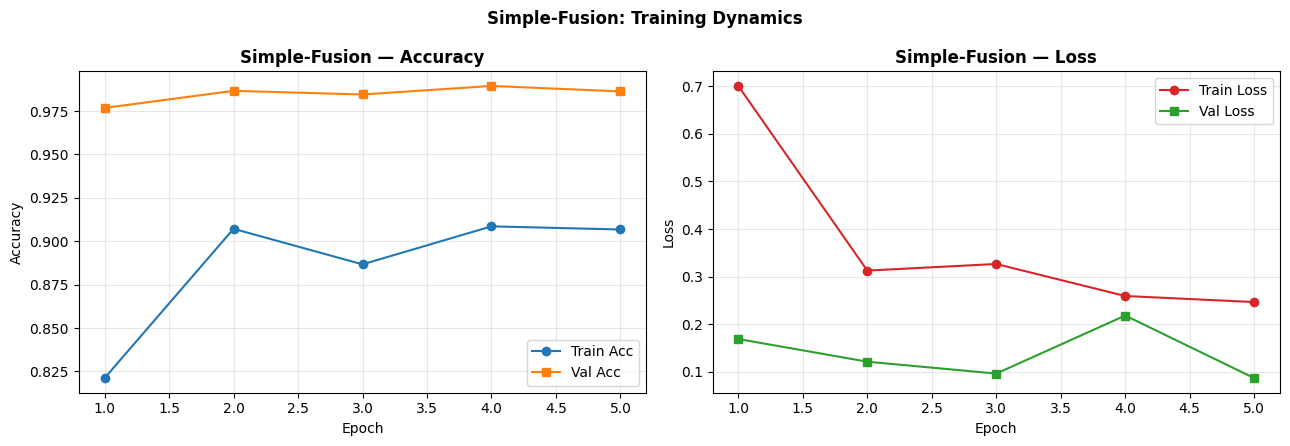

  [saved] Curves          -> /content/drive/MyDrive/CropXNet_Outputs/Simple-Fusion_curves.png


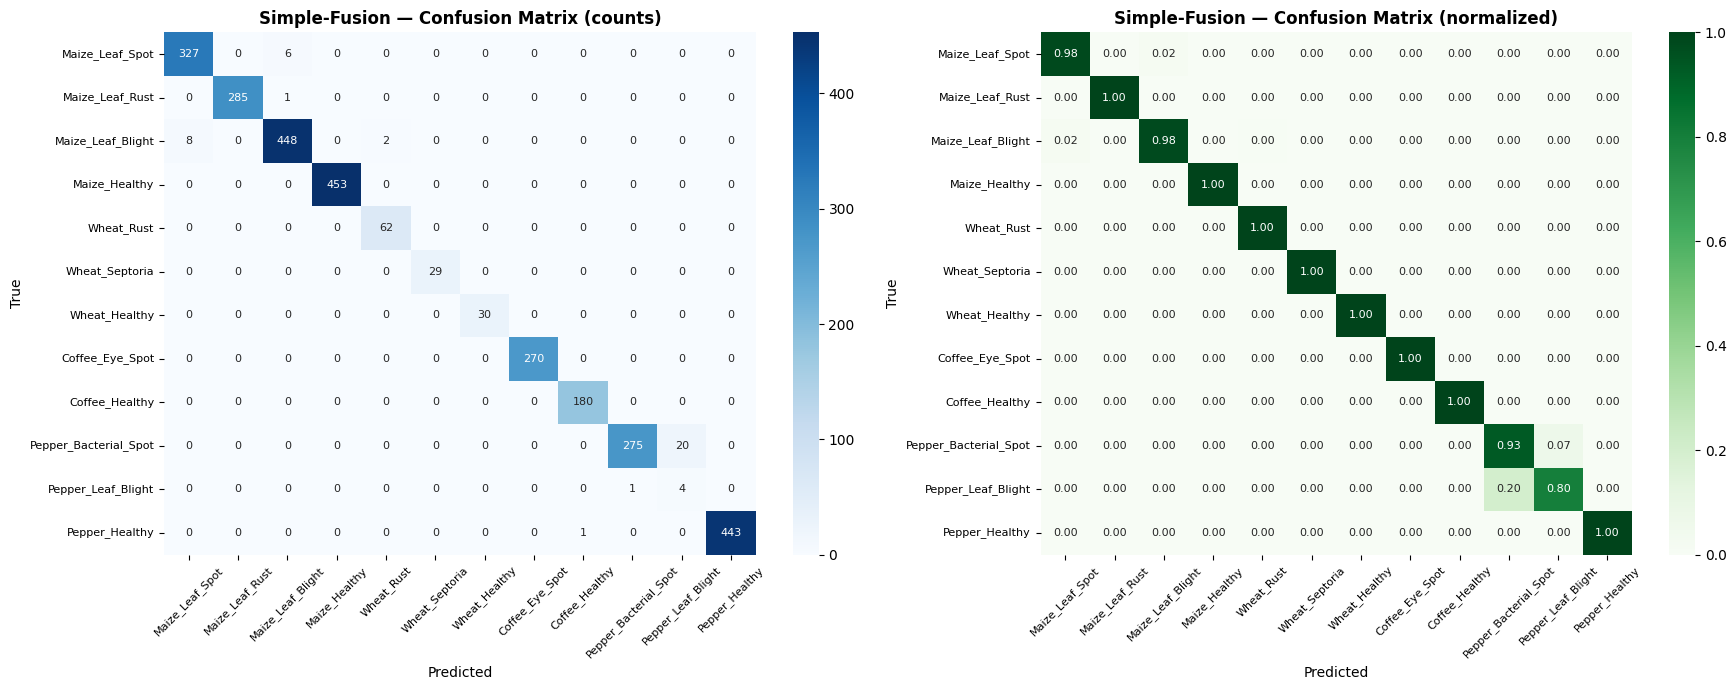

  [saved] Confusion matrix -> /content/drive/MyDrive/CropXNet_Outputs/Simple-Fusion_confusion_matrix.png

===== Classification Report — Simple-Fusion =====
                       precision    recall  f1-score   support

      Maize_Leaf_Spot     0.9761    0.9820    0.9790       333
      Maize_Leaf_Rust     1.0000    0.9965    0.9982       286
    Maize_Leaf_Blight     0.9846    0.9782    0.9814       458
        Maize_Healthy     1.0000    1.0000    1.0000       453
           Wheat_Rust     0.9688    1.0000    0.9841        62
       Wheat_Septoria     1.0000    1.0000    1.0000        29
        Wheat_Healthy     1.0000    1.0000    1.0000        30
      Coffee_Eye_Spot     1.0000    1.0000    1.0000       270
       Coffee_Healthy     0.9945    1.0000    0.9972       180
Pepper_Bacterial_Spot     0.9964    0.9322    0.9632       295
   Pepper_Leaf_Blight     0.1667    0.8000    0.2759         5
       Pepper_Healthy     1.0000    0.9977    0.9989       444

             accuracy  

In [ ]:
# ============================================================
# CELL 9: Ablation Models (CNN-Only, ViT-Only, Simple-Fusion)
# ============================================================
ablation_variants = {
    'CNN-Only':      'cnn_only',
    'ViT-Only':      'vit_only',
    'Simple-Fusion': 'simple_fusion',
}

for display_name, variant_key in ablation_variants.items():
    print('\n' + '#' * 70)
    print(f'#  ABLATION : {display_name}')
    print('#' * 70)
    m, h = train_model(variant_key, train_loader, val_loader,
                       class_weights, CFG.DEVICE, epochs=CFG.EPOCHS, tag='Abl')
    overall, yt, yp, cm, cmn, rpt = evaluate_and_report(
        m, test_loader, h, model_name=display_name,
        class_names=CFG.CLASSES, out_dir=CFG.OUTPUT_DIR, device=CFG.DEVICE)
    overall['Params (M)'] = sum(p.numel() for p in m.parameters()) / 1e6
    all_overall[display_name] = overall
    all_reports[display_name] = rpt
    all_preds[display_name]   = (yt, yp)
    all_models[display_name]  = m
    torch.save(m.state_dict(), f'{CFG.OUTPUT_DIR}/{display_name}_best.pth')


######################################################################
#  BASELINE : ResNet-50
######################################################################
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s]


train:   0%|          | 0/500 [00:00<?, ?it/s]

[Base][resnet50] Ep 01/5 | trL 0.7234 trA 0.8257 | vaL 0.1256 vaA 0.9768


train:   0%|          | 0/500 [00:00<?, ?it/s]

...

train:   0%|          | 0/500 [00:00<?, ?it/s]

[Base][resnet50] Ep 04/5 | trL 0.2143 trA 0.9007 | vaL 0.2376 vaA 0.9877


train:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c220f8c6980>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Base][resnet50] Ep 05/5 | trL 0.1849 trA 0.9170 | vaL 0.2101 vaA 0.9856


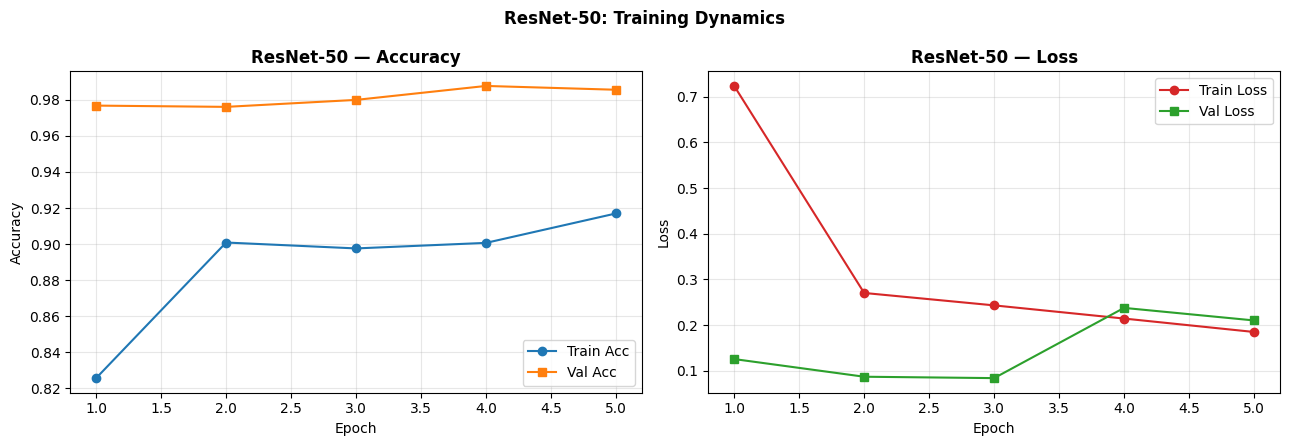

  [saved] Curves          -> /content/drive/MyDrive/CropXNet_Outputs/ResNet-50_curves.png


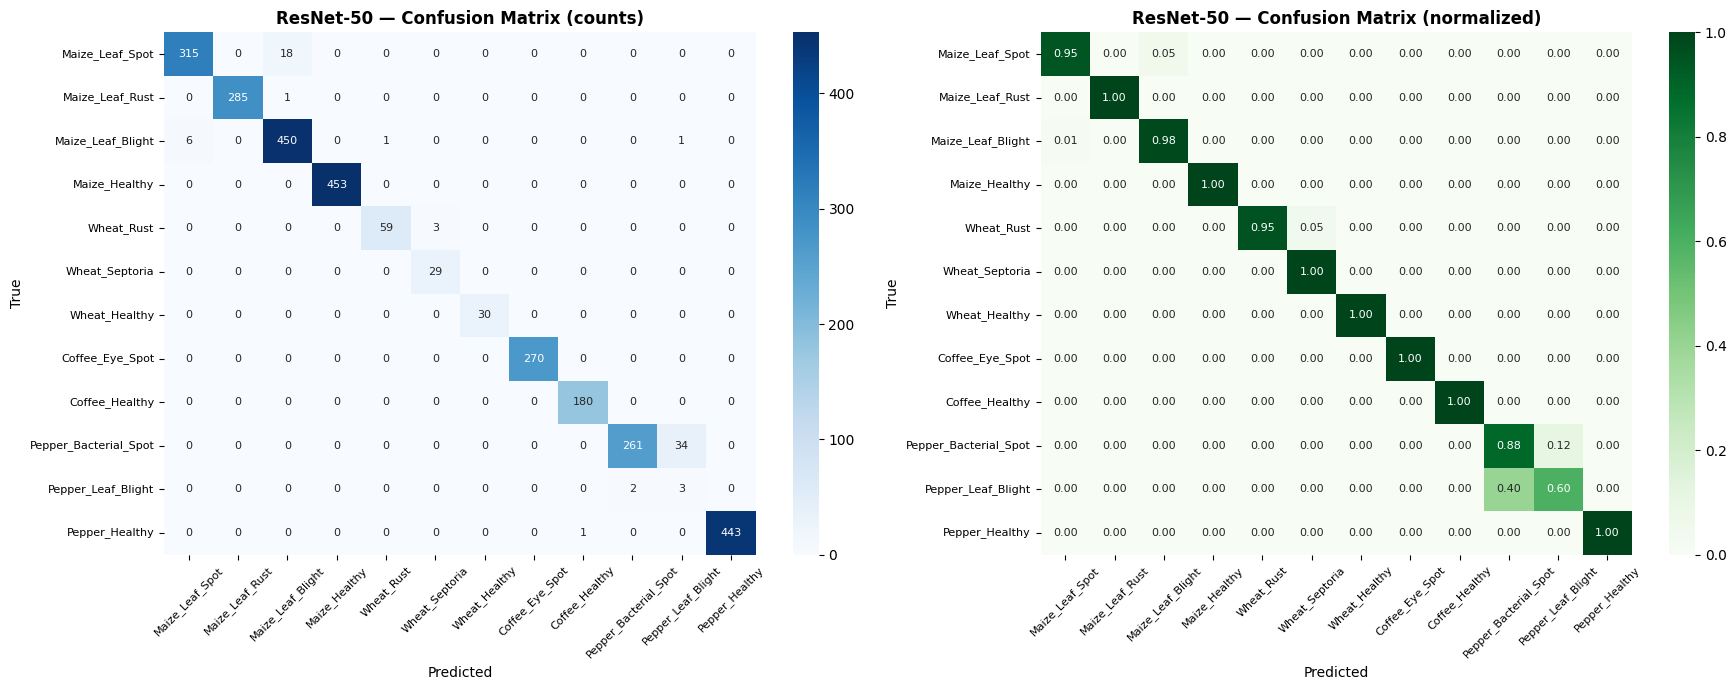

  [saved] Confusion matrix -> /content/drive/MyDrive/CropXNet_Outputs/ResNet-50_confusion_matrix.png

===== Classification Report — ResNet-50 =====
                       precision    recall  f1-score   support

      Maize_Leaf_Spot     0.9813    0.9459    0.9633       333
      Maize_Leaf_Rust     1.0000    0.9965    0.9982       286
    Maize_Leaf_Blight     0.9595    0.9825    0.9709       458
        Maize_Healthy     1.0000    1.0000    1.0000       453
           Wheat_Rust     0.9833    0.9516    0.9672        62
       Wheat_Septoria     0.9062    1.0000    0.9508        29
        Wheat_Healthy     1.0000    1.0000    1.0000        30
      Coffee_Eye_Spot     1.0000    1.0000    1.0000       270
       Coffee_Healthy     0.9945    1.0000    0.9972       180
Pepper_Bacterial_Spot     0.9924    0.8847    0.9355       295
   Pepper_Leaf_Blight     0.0789    0.6000    0.1395         5
       Pepper_Healthy     1.0000    0.9977    0.9989       444

             accuracy          

100%|██████████| 74.5M/74.5M [00:01<00:00, 65.6MB/s]


train:   0%|          | 0/500 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# CELL 10: Baselines (ResNet-50, EfficientNet-B4, ViT-Base)
# ============================================================
baseline_models = {
    'ResNet-50':       'resnet50',
    'EfficientNet-B4': 'effnetb4',
    'ViT-Base':        'vitbase',
}

for display_name, variant_key in baseline_models.items():
    print('\n' + '#' * 70)
    print(f'#  BASELINE : {display_name}')
    print('#' * 70)
    m, h = train_model(variant_key, train_loader, val_loader,
                       class_weights, CFG.DEVICE, epochs=CFG.EPOCHS, tag='Base')
    overall, yt, yp, cm, cmn, rpt = evaluate_and_report(
        m, test_loader, h, model_name=display_name,
        class_names=CFG.CLASSES, out_dir=CFG.OUTPUT_DIR, device=CFG.DEVICE)
    overall['Params (M)'] = sum(p.numel() for p in m.parameters()) / 1e6
    all_overall[display_name] = overall
    all_reports[display_name] = rpt
    all_preds[display_name]   = (yt, yp)
    all_models[display_name]  = m
    torch.save(m.state_dict(), f'{CFG.OUTPUT_DIR}/{display_name}_best.pth')

In [ ]:
# ============================================================
# CELL 11: Consolidated Comparison Tables & Plots
# ============================================================
print('\n' + '=' * 70)
print('  CONSOLIDATED RESULTS')
print('=' * 70)

# ---- Table 4: Comparative performance ----
table_all = pd.DataFrame(all_overall).T
table_all = table_all[['Accuracy', 'Precision', 'Recall', 'F1', 'Params (M)']].round(4)
print('\n=== Table 4: Comparative Performance ===')
print(table_all.to_string())
table_all.to_csv(f'{CFG.OUTPUT_DIR}/Table4_comparative_performance.csv')

# ---- Bar chart: accuracy across models ----
fig, ax = plt.subplots(figsize=(12, 5))
order = table_all['Accuracy'].sort_values(ascending=False)
colors = ['#E63946' if m == 'CropXNet-Hybrid' else '#457B9D' for m in order.index]
bars = ax.bar(range(len(order)), order.values, color=colors, edgecolor='black')
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order.index, rotation=30, ha='right')
ax.set_ylabel('Accuracy (%)'); ax.set_ylim(80, 100)
ax.set_title('Model Comparison — Test Accuracy', fontweight='bold')
for b, v in zip(bars, order.values):
    ax.text(b.get_x()+b.get_width()/2, v+0.3, f'{v:.2f}%',
            ha='center', fontsize=9, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/comparison_accuracy_bar.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- Table 5: Ablation ----
abl_order = ['CNN-Only', 'ViT-Only', 'Simple-Fusion', 'CropXNet-Hybrid']
table5 = table_all.loc[[k for k in abl_order if k in table_all.index]]
print('\n=== Table 5: Ablation Study ===')
print(table5.to_string())
table5.to_csv(f'{CFG.OUTPUT_DIR}/Table5_ablation_study.csv')

# ---- Ablation comparison bar ----
fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['Accuracy', 'Precision', 'Recall']
x = np.arange(len(table5)); width = 0.25
for i, m in enumerate(metrics):
    ax.bar(x + i*width, table5[m], width, label=m, edgecolor='black')
ax.set_xticks(x + width); ax.set_xticklabels(table5.index, rotation=15)
ax.set_ylabel('Score (%)'); ax.set_ylim(85, 100)
ax.set_title('Ablation Study — Metric Comparison', fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for i, m in enumerate(metrics):
    for xi, v in zip(x + i*width, table5[m]):
        ax.text(xi, v+0.2, f'{v:.1f}', ha='center', fontsize=7)
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/ablation_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- Per-class F1 heatmap ----
per_class_f1 = {}
for name, rpt in all_reports.items():
    if 'f1-score' in rpt.columns:
        per_class_f1[name] = rpt.loc[CFG.CLASSES, 'f1-score']
per_class_df = pd.DataFrame(per_class_f1).round(4)
print('\n=== Per-Class F1 Across All Models ===')
print(per_class_df.to_string())
per_class_df.to_csv(f'{CFG.OUTPUT_DIR}/per_class_F1_all_models.csv')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(per_class_df, annot=True, fmt='.3f', cmap='RdYlGn',
            cbar=True, ax=ax, vmin=0.7, vmax=1.0, annot_kws={'size': 8})
ax.set_title('Per-Class F1-Score — All Models', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/per_class_F1_heatmap.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# ---- McNemar tests ----
print('\n=== McNemar Tests (CropXNet-Hybrid vs others) ===')
yt_cx, yp_cx = all_preds['CropXNet-Hybrid']
for name, (yt, yp) in all_preds.items():
    if name == 'CropXNet-Hybrid': continue
    chi2, p = mcnemar_test(yt_cx, yp, yp_cx)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f'  vs {name:18s}  chi2={chi2:6.2f}  p={p:.4e}  {sig}')

In [ ]:
# ============================================================
# CELL 12: Robustness under Field Degradations
# ============================================================
def apply_illumination(x, factor): return torch.clamp(x * factor, 0, 1)

def apply_motion_blur(x, ksize=7):
    kernel = torch.zeros(1, 1, ksize, ksize, device=x.device)
    kernel[0, 0, ksize // 2, :] = 1.0 / ksize
    kernel = kernel.repeat(x.size(1), 1, 1, 1)
    pad = ksize // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode='reflect'),
                    kernel, groups=x.size(1))

def apply_occlusion(x, frac=0.25):
    B, C, H, W = x.shape; s = int(H * frac); out = x.clone()
    for i in range(B):
        y1 = random.randint(0, H - s); x1 = random.randint(0, W - s)
        out[i, :, y1:y1+s, x1:x1+s] = 0.0
    return out

def apply_gauss_noise(x, std=0.05):
    return torch.clamp(x + torch.randn_like(x) * std, 0, 1)

@torch.no_grad()
def eval_with_perturbation(model, loader, perturb_fn, device):
    model.eval(); correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        x = perturb_fn(x)
        with autocast(): out = model(x)
        correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return correct / total * 100

cx_model = all_models['CropXNet-Hybrid'].eval()
robustness_results = {'Clean': eval_with_perturbation(
    cx_model, test_loader, lambda x: x, CFG.DEVICE)}

for f in [0.5, 0.7, 0.85, 1.15, 1.3, 1.5]:
    robustness_results[f'Illum_{f}x'] = eval_with_perturbation(
        cx_model, test_loader, lambda x, f=f: apply_illumination(x, f), CFG.DEVICE)
for k in [3, 5, 7, 9]:
    robustness_results[f'Blur_k{k}'] = eval_with_perturbation(
        cx_model, test_loader, lambda x, k=k: apply_motion_blur(x, k), CFG.DEVICE)
for frac in [0.10, 0.20, 0.30]:
    robustness_results[f'Occl_{int(frac*100)}%'] = eval_with_perturbation(
        cx_model, test_loader, lambda x, fr=frac: apply_occlusion(x, fr), CFG.DEVICE)
for std in [0.02, 0.05, 0.10]:
    robustness_results[f'Noise_{std}'] = eval_with_perturbation(
        cx_model, test_loader, lambda x, s=std: apply_gauss_noise(x, s), CFG.DEVICE)

rob_df = pd.DataFrame(list(robustness_results.items()),
                      columns=['Perturbation', 'Accuracy (%)'])
print('\n=== Robustness Results ===')
print(rob_df.round(2).to_string(index=False))
rob_df.to_csv(f'{CFG.OUTPUT_DIR}/robustness.csv', index=False)

# ---- Bar chart ----
fig, ax = plt.subplots(figsize=(14, 5))
colors = ['green'] + ['tab:red'] * (len(rob_df) - 1)
ax.bar(range(len(rob_df)), rob_df['Accuracy (%)'], color=colors, edgecolor='black')
ax.axhline(robustness_results['Clean'], color='green', ls='--', lw=1, alpha=0.5)
ax.set_xticks(range(len(rob_df)))
ax.set_xticklabels(rob_df['Perturbation'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Accuracy (%)'); ax.set_ylim(80, 100)
ax.set_title('Robustness — CropXNet-Hybrid under Degradations', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/robustness_chart.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

clean = robustness_results['Clean']
drops = [clean - v for k, v in robustness_results.items() if k != 'Clean']
print(f'\nClean: {clean:.2f}%   Mean drop: {np.mean(drops):.2f}%   Worst: {np.max(drops):.2f}%')

In [ ]:
# ============================================================
# CELL 13: KD + 8-bit Quantization (Edge Deployment)
# ============================================================
print('\n' + '=' * 70)
print('  KNOWLEDGE DISTILLATION + 8-BIT QUANTIZATION')
print('=' * 70)

teacher = all_models['CropXNet-Hybrid'].eval()

class StudentNet(nn.Module):
    def __init__(self, nc=12):
        super().__init__()
        self.backbone = timm.create_model('mobilenetv3_small_100',
                                          pretrained=True, num_classes=0)
        self.head = nn.Linear(self.backbone.num_features, nc)
    def forward(self, x): return self.head(self.backbone(x))

student = StudentNet(CFG.NUM_CLASSES).to(CFG.DEVICE)
opt = AdamW(student.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
scaler = GradScaler()

def distillation_loss(s_logits, t_logits, y, T=4.0, a=0.7):
    ce = F.cross_entropy(s_logits, y)
    kl = F.kl_div(F.log_softmax(s_logits / T, dim=-1),
                  F.softmax(t_logits / T, dim=-1), reduction='batchmean') * (T * T)
    return a * ce + (1 - a) * kl

for ep in range(1, 21):
    student.train(); tl, tc, tt = 0, 0, 0
    for x, y in tqdm(train_loader, desc=f'KD ep{ep}', leave=False):
        x, y = x.to(CFG.DEVICE), y.to(CFG.DEVICE)
        with torch.no_grad():
            with autocast(): t_out = teacher(x)
        with autocast():
            s_out = student(x); loss = distillation_loss(s_out, t_out, y)
        opt.zero_grad(); scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        tl += loss.item() * x.size(0)
        tc += (s_out.argmax(1) == y).sum().item(); tt += x.size(0)
    print(f'  KD ep {ep:02d}: loss={tl/tt:.4f}  acc={tc/tt:.4f}')

_, s_acc, _, _ = evaluate(student, test_loader, criterion_eval, CFG.DEVICE)
print(f'\nStudent accuracy after KD: {s_acc*100:.2f}%')

# ---- 8-bit dynamic quantization ----
student_cpu = copy.deepcopy(student).cpu().eval()
quantized = torch.quantization.quantize_dynamic(student_cpu, {nn.Linear}, dtype=torch.qint8)

def model_size_mb(m):
    torch.save(m.state_dict(), '/tmp/_m.pt')
    return os.path.getsize('/tmp/_m.pt') / (1024 * 1024)

size_fp32 = model_size_mb(student_cpu)
size_int8 = model_size_mb(quantized)
print(f'\nFP32 size : {size_fp32:.2f} MB')
print(f'INT8 size : {size_int8:.2f} MB')
print(f'Reduction : {(1 - size_int8/size_fp32)*100:.1f}%')

x_dummy = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    for _ in range(5): _ = quantized(x_dummy)
    t0 = time.time()
    for _ in range(50): _ = quantized(x_dummy)
    lat = (time.time() - t0) / 50 * 1000
print(f'CPU latency: {lat:.1f} ms/image')

In [ ]:
# ============================================================
# CELL 14: Verify All Artifacts + Final Summary
# ============================================================
print('\n' + '=' * 70)
print('  ARTIFACT VERIFICATION')
print('=' * 70)

models_list = ['CropXNet-Hybrid', 'CNN-Only', 'ViT-Only', 'Simple-Fusion',
               'ResNet-50', 'EfficientNet-B4', 'ViT-Base']
for m in models_list:
    print(f'\n--- {m} ---')
    for suffix in ['curves.png', 'confusion_matrix.png', 'classification_report.csv']:
        p = f'{CFG.OUTPUT_DIR}/{m}_{suffix}'
        print(f'  {"✅" if os.path.exists(p) else "❌ MISSING"}  {os.path.basename(p)}')

print('\n--- Consolidated files ---')
for f in ['Table4_comparative_performance.csv', 'Table5_ablation_study.csv',
          'per_class_F1_all_models.csv', 'robustness.csv',
          'dataset_class_distribution.png', 'dataset_samples.png',
          'dataset_imbalance.png', 'comparison_accuracy_bar.png',
          'ablation_comparison_bar.png', 'per_class_F1_heatmap.png',
          'robustness_chart.png']:
    p = f'{CFG.OUTPUT_DIR}/{f}'
    print(f'  {"✅" if os.path.exists(p) else "❌ MISSING"}  {f}')

# ---- Final summary ----
print('\n' + '=' * 70)
print('  FINAL SUMMARY — CropXNet-Hybrid')
print('=' * 70)
cx = all_overall['CropXNet-Hybrid']
summary = {
    'Dataset - Total Images':    f'{len(df)}',
    'Dataset - Local':           f'{len(local_df)}',
    'Dataset - Public':          f'{len(public_df)}',
    'Train / Val / Test':        f'{len(train_df)} / {len(val_df)} / {len(test_df)}',
    'Overall Accuracy (%)':      f"{cx['Accuracy']:.2f}",
    'Precision (%)':             f"{cx['Precision']:.2f}",
    'Recall (%)':                f"{cx['Recall']:.2f}",
    'F1-Score':                  f"{cx['F1']:.4f}",
    'Total Params (M)':          f"{cx['Params (M)']:.2f}",
    'Quantized Size (MB)':       f'{size_int8:.1f}',
    'Size Reduction (%)':        f'{(1 - size_int8/size_fp32)*100:.1f}',
    'CPU Latency (ms)':          f'{lat:.1f}',
    'Clean Test Acc (%)':        f"{robustness_results['Clean']:.2f}",
    'Mean Robustness Drop':      f'{np.mean(drops):.2f}%',
    'Worst Robustness Drop':     f'{np.max(drops):.2f}%',
}
for k, v in summary.items():
    print(f'  {k:25s}: {v}')

with open(f'{CFG.OUTPUT_DIR}/summary.json', 'w') as f:
    json.dump({'summary': summary, 'overall': all_overall,
               'robustness': robustness_results}, f, indent=2)

print(f'\nAll outputs saved to: {CFG.OUTPUT_DIR}')
print('DONE.')